In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
DATA_DIR = "/content/drive/MyDrive/Colab Notebooks/dataset/Diabetic Retinopathy"
print(os.listdir(DATA_DIR))

Mounted at /content/drive
['Details.txt', 'DR', 'No DR', 'confusion_matrix.png', 'training_curves.png', 'dr_efficientnet_b5.h5']


In [ ]:
# Diabetic Retinopathy Detection (Binary: DR vs No DR)
# EfficientNet transfer learning on APTOS 2019

import os, numpy as np, tensorflow as tf, matplotlib.pyplot as plt, seaborn as sns
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB3
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve)

SEED = 42
tf.random.set_seed(SEED); np.random.seed(SEED)


DATA_DIR   = "/content/drive/MyDrive/Colab Notebooks/dataset/Diabetic Retinopathy"
IMG_SIZE   = 300
BATCH_SIZE = 16
HEAD_EPOCHS, FT_EPOCHS = 10, 15
CLASS_NAMES = ["No DR", "DR"]
AUTOTUNE = tf.data.AUTOTUNE

In [ ]:
paths, labels = [], []
for label, cls in enumerate(CLASS_NAMES):
    folder = os.path.join(DATA_DIR, cls)
    for f in os.listdir(folder):
        if f.lower().endswith((".png", ".jpg", ".jpeg")):
            paths.append(os.path.join(folder, f)); labels.append(label)
paths, labels = np.array(paths), np.array(labels)
print({c: int((labels == i).sum()) for i, c in enumerate(CLASS_NAMES)})


{'No DR': 1805, 'DR': 120}


In [ ]:
#Train(70/15/15)
X_train, X_tmp, y_train, y_tmp = train_test_split(
    paths, labels, test_size=0.30, stratify=labels, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print(f"train={len(X_train)}  val={len(X_val)}  test={len(X_test)}")



train=1347  val=289  test=289


In [ ]:
def load_image(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return tf.cast(img, tf.float32), label
augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.15),
])

def make_ds(X, y, training):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training: ds = ds.shuffle(len(X), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    if training:
        ds = ds.map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds = make_ds(X_train, y_train, True)
val_ds   = make_ds(X_val,   y_val,   False)
test_ds  = make_ds(X_test,  y_test,  False)

# Class weights for imbalance
cw = compute_class_weight("balanced", classes=np.unique(y_train), y=y_train)
class_weight = dict(enumerate(cw)); print("class weights:", class_weight)



class weights: {0: np.float64(0.5332541567695962), 1: np.float64(8.017857142857142)}


In [7]:
# Metrics
def get_metrics():
    return [tf.keras.metrics.BinaryAccuracy(name="acc"),
            tf.keras.metrics.AUC(name="auc"),
            tf.keras.metrics.Recall(name="sensitivity"),
            tf.keras.metrics.Precision(name="precision")]

def callbacks(tag):
    return [
        tf.keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=5,
                                         restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_auc", mode="max",
                                             factor=0.3, patience=2),
        tf.keras.callbacks.ModelCheckpoint(f"best_{tag}.keras", monitor="val_auc",
                                           mode="max", save_best_only=True),
    ]

# ---------------- Model ----------------
base = EfficientNetB3(include_top=False, weights="imagenet",
                      input_shape=(IMG_SIZE, IMG_SIZE, 3))
base.trainable = False

inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
x = base(inp, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
out = layers.Dense(1, activation="sigmoid")(x)
model = Model(inp, out)

# Stage 1: train head
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="binary_crossentropy", metrics=get_metrics())
h1 = model.fit(train_ds, validation_data=val_ds, epochs=HEAD_EPOCHS,
               class_weight=class_weight, callbacks=callbacks("head"))

# Stage 2: fine-tune top layers (BatchNorm stays frozen)
base.trainable = True
for layer in base.layers[:-40]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss="binary_crossentropy", metrics=get_metrics())
h2 = model.fit(train_ds, validation_data=val_ds, epochs=FT_EPOCHS,
               class_weight=class_weight, callbacks=callbacks("finetune"))

# ---------------- Evaluation on test set ----------------
y_prob = model.predict(test_ds).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4))
auc = roc_auc_score(y_test, y_prob)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f"ROC-AUC: {auc:.4f} | Sensitivity: {tp/(tp+fn):.4f} | Specificity: {tn/(tn+fp):.4f}")

os.makedirs("results", exist_ok=True)

43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 587s 7s/step - acc: 0.8337 - auc: 0.8339 - loss: 0.5321 - precision: 0.2244 - sensitivity: 0.6786 - val_acc: 0.9758 - val_auc: 0.9730 - val_loss: 0.2868 - val_precision: 0.8235 - val_sensitivity: 0.7778 - learning_rate: 0.0010
Epoch 2/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 582s 7s/step - acc: 0.8760 - auc: 0.9514 - loss: 0.3577 - precision: 0.3219 - sensitivity: 0.8929 - val_acc: 0.9654 - val_auc: 0.9811 - val_loss: 0.2266 - val_precision: 0.6667 - val_sensitivity: 0.8889 - learning_rate: 0.0010
Epoch 3/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 579s 7s/step - acc: 0.8916 - auc: 0.9732 - loss: 0.2703 - precision: 0.3628 - sensitivity: 0.9762 - val_acc: 0.9792 - val_auc: 0.9846 - val_loss: 0.1654 - val_precision: 0.8000 - val_sensitivity: 0.8889 - learning_rate: 0.0010
Epoch 4/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 583s 7s/step - acc: 0.8857 - auc: 0.9742 - loss: 0.2523 - precision: 0.3491 - sensitivity: 0.9643 - val_acc: 0.9446 

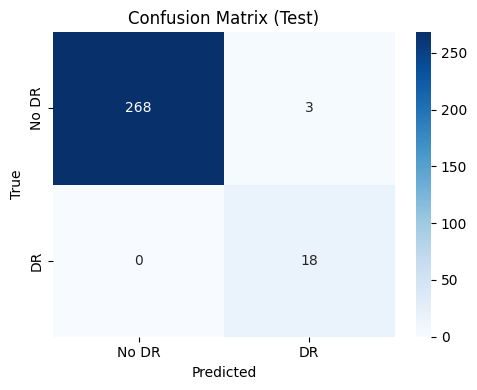

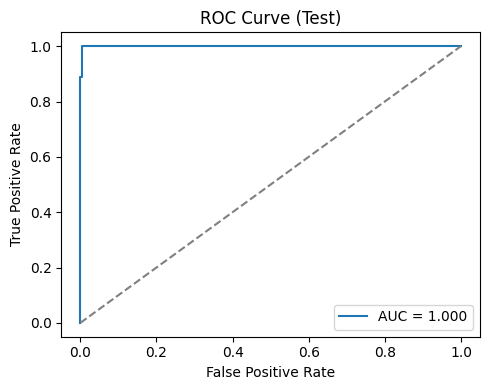

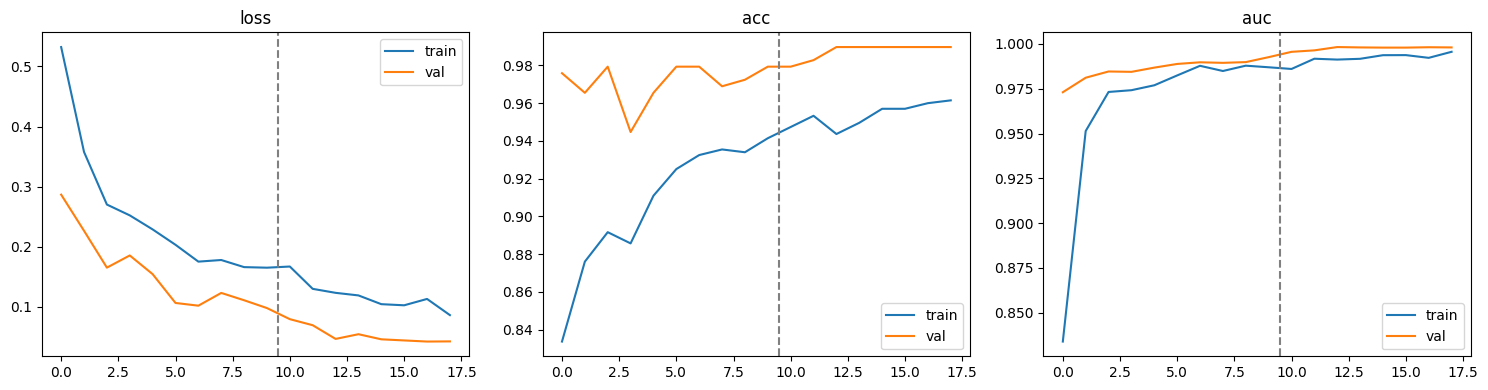

In [8]:



# Confusion matrix
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion Matrix (Test)")
plt.tight_layout(); plt.savefig("results/confusion_matrix.png", dpi=200); plt.show()

# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}"); plt.plot([0, 1], [0, 1], "--", c="gray")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.legend()
plt.title("ROC Curve (Test)"); plt.tight_layout()
plt.savefig("results/roc_curve.png", dpi=200); plt.show()

# Training curves
hist = {k: h1.history[k] + h2.history[k] for k in h1.history if k in h2.history}
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, m in zip(ax, ["loss", "acc", "auc"]):
    a.plot(hist[m], label="train"); a.plot(hist[f"val_{m}"], label="val")
    a.axvline(len(h1.history["loss"]) - 0.5, ls="--", c="gray")  # fine-tune start
    a.set_title(m); a.legend()
plt.tight_layout(); plt.savefig("results/training_curves.png", dpi=200); plt.show()

model.save("dr_efficientnet.keras")